# Quality 130/30 Fund – Portfolio Construction and Diversification
**EC4430 Portfolio Management** · Investment horizon: 12 months · Benchmark: S&P 500

This notebook rebuilds the fund from raw S&P Capital IQ data and tests whether it is well diversified.

| Step | What it does |
|---|---|
| 1 | Score every S&P 500 stock on **quality** (Asness, Frazzini & Pedersen, 2013) |
| 2 | Select **27 stocks** (19 long, 8 short) and compute **130/30 weights** |
| 3 | Check **diversification by construction** (concentration, sectors, position sizes) |
| 4 | Test diversification **with real data**: correlations of 36 months of returns |
| 5 | Historical risk check and limitations |

In [1]:
import os, sys, pandas as pd
from IPython.display import Image, display
if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")                      # run everything from the repository root
sys.path.insert(0, "src")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

## Step 1 – Quality scores

Four pillars, each measure standardised **within its GICS sector** as a z-score, winsorised at 5/95% and capped at ±3:

| Pillar | Measure |
|---|---|
| Profitability | Return on equity; gross profit / total assets |
| Growth | 5-year change in gross profit / total assets (FY2020 → latest) |
| Safety | Beta and total debt / total assets (multiplied by −1: lower = safer) |
| Payout | (Dividends + buybacks − share issuance) / net income |

Composite quality score = average of the four pillar scores.

In [2]:
from build_portfolio import load_screen, quality_scores, build
universe = quality_scores(load_screen("data/sp500_screen_capiq.xlsx"))
print(f"{len(universe)} S&P 500 stocks scored across {universe.sector.nunique()} sectors")
universe.sort_values("quality", ascending=False)[["ticker", "company", "sector", "profitability", "growth_z", "safety", "payout_z", "quality"]].head(10).round(2)

500 S&P 500 stocks scored across 11 sectors


,ticker,company,sector,profitability,growth_z,safety,payout_z,quality
473,V,Visa Inc.,Financials,2.93,3.00,-0.04,0.39,1.57
319,NRG,"NRG Energy, Inc.",Utilities,3.00,1.75,-2.05,3.00,1.42
284,MA,Mastercard Incorporated,Financials,3.00,2.90,-0.47,0.21,1.41
3,ABBV,AbbVie Inc.,Health Care,1.33,1.31,-0.17,3.00,1.37
391,LUV,Southwest Airlines Co.,Industrials,-0.70,2.81,-0.07,3.00,1.26
118,CSGP,"CoStar Group, Inc.",Real Estate,1.17,1.03,1.07,1.73,1.25
197,IT,"Gartner, Inc.",Information Technology,1.68,1.53,-0.03,1.75,1.23
90,CF,"CF Industries Holdings, Inc.",Materials,0.49,2.54,1.36,0.31,1.17
431,KR,The Kroger Co.,Consumer Staples,0.68,1.20,0.05,2.71,1.16
5,ADBE,Adobe Inc.,Information Technology,1.39,2.09,0.57,0.52,1.14


## Step 2 – Stock selection and weights

**Longs** – top 20% quality in their sector, then filters taken from the analyst's capital market expectations:
- forward P/E ≤ 1.5× sector median (*quality at a fair price*)
- ROE ≥ 10% (*sustainable profitability*), debt/assets ≤ 0.5 (*rates stay high*), beta ≤ 1.3, no airlines (*$114 oil*)
- at most 2 per sector

**Shorts** – bottom 20% quality in their sector, priced above the sector median P/E (or no forward earnings); the 8 lowest scores, at most 2 per sector.

**Weights** – proportional to the quality score (130% long, 30% short), capped at 10% per long and 6% per short. Score-weighting is used instead of mean–variance optimisation, whose weights are very sensitive to errors in expected returns.

In [3]:
port = build(universe)
port.to_csv("output/portfolio.csv", index=False)
show = port[["side", "ticker", "company", "sector", "fpe", "sector_pe", "roe", "beta", "lev", "quality", "weight", "shares"]].copy()
show["weight"] = (show.weight * 100).round(1)
print(f"Long {port.weight[port.weight>0].sum():.0%} | Short {port.weight[port.weight<0].sum():.0%} | Net {port.weight.sum():.0%}")
show.round(2)

Long 130% | Short -30% | Net 100%


,side,ticker,company,sector,fpe,sector_pe,roe,beta,lev,quality,weight,shares
197,Long,IT,"Gartner, Inc.",Information Technology,11.95,18.36,86.86,0.82,0.41,1.23,10.0,53
90,Long,CF,"CF Industries Holdings, Inc.",Materials,9.48,16.79,23.40,-0.01,0.26,1.17,10.0,84
431,Long,KR,The Kroger Co.,Consumer Staples,12.63,17.17,14.40,-0.22,0.49,1.16,10.0,148
5,Long,ADBE,Adobe Inc.,Information Technology,8.91,18.36,55.43,0.80,0.23,1.14,10.0,42
1,Long,AOS,A. O. Smith Corporation,Industrials,17.60,19.91,29.20,0.67,0.06,0.88,9.6,149
479,Long,GWW,"W.W. Grainger, Inc.",Industrials,28.21,19.91,46.10,0.68,0.32,0.76,8.3,6
309,Long,NEM,Newmont Corporation,Materials,13.50,16.79,22.34,0.84,0.10,0.74,8.0,66
232,Long,INCY,Incyte Corporation,Health Care,15.18,18.96,29.87,0.52,0.01,0.71,7.8,65
221,Long,HST,"Host Hotels & Resorts, Inc.",Real Estate,24.49,35.80,11.49,0.98,0.43,0.66,7.2,293
234,Long,PODD,Insulet Corporation,Health Care,19.53,18.96,18.12,0.77,0.31,0.66,7.2,49


### Worked example
- **Gartner (long):** Q = +1.23 → uncapped weight 130% × 1.23 / 12.97 = 12.3% → capped at **10%**. Forward P/E 12.0× vs sector 18.4×.
- **Tesla (short):** Q = −0.99 → weight −30% × 0.99 / 9.11 = **−3.3%**. Forward P/E 167.6× vs sector 18.7×.

## Step 3 – Diversification by construction
Evans & Archer (1968) and Statman (1987) show that 20–30 stocks remove most diversifiable risk. The *effective number of stocks* (1 / Herfindahl index) adjusts the count for unequal weights.

In [4]:
%run src/diversification.py

                                      Metric           Value
                            Number of stocks              27
          Effective number of stocks (1/HHI)            23.0
                      Herfindahl index (HHI)           0.043
                     Largest single position             10%
                Top-5 positions (% of gross)             31%
                             Sectors covered        11 of 11
                 Largest net sector exposure 18% (Materials)
Diversifiable variance removed (1 - 1/N_eff)             96%


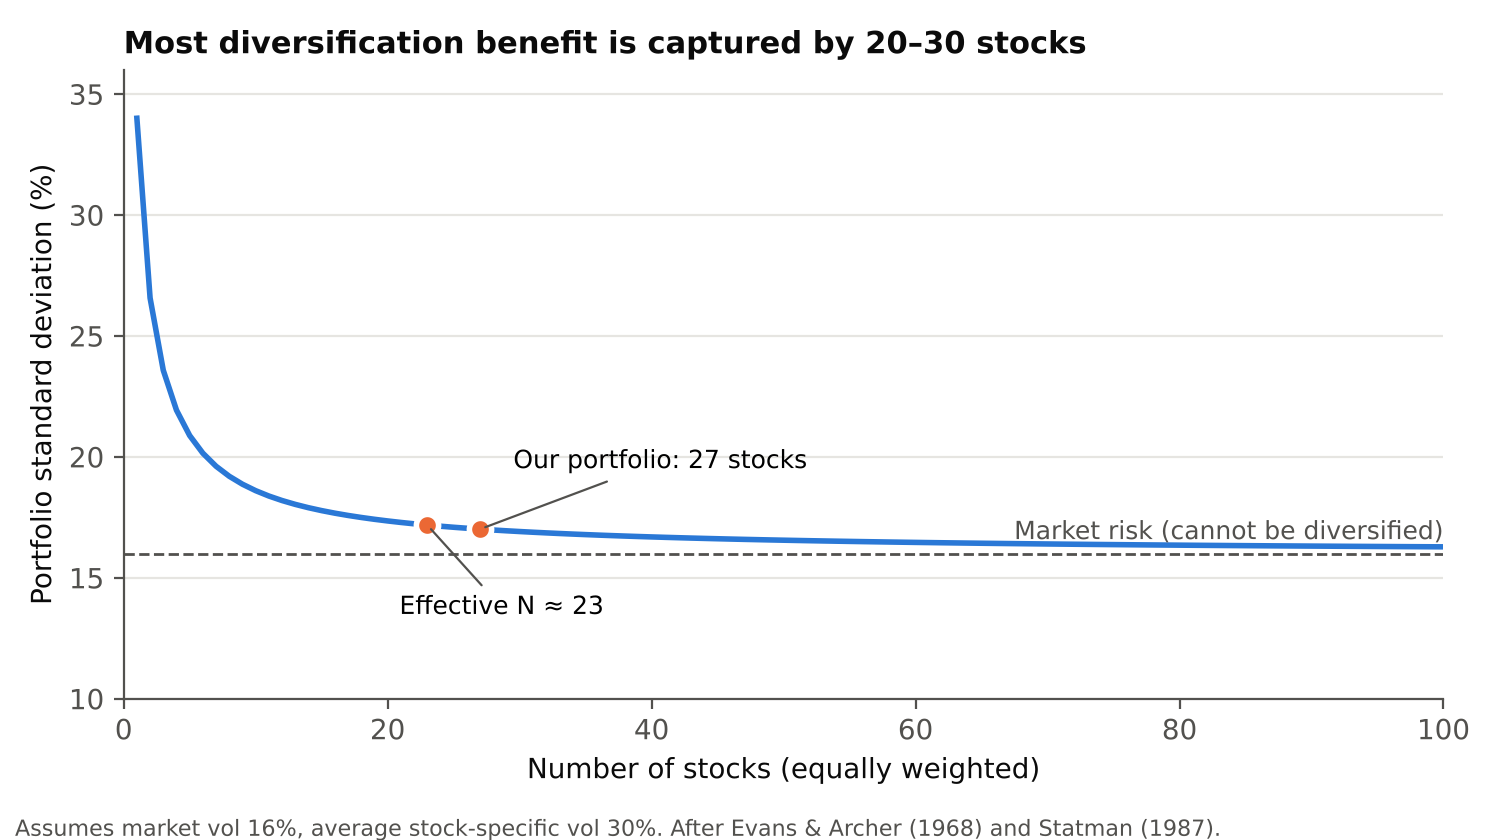

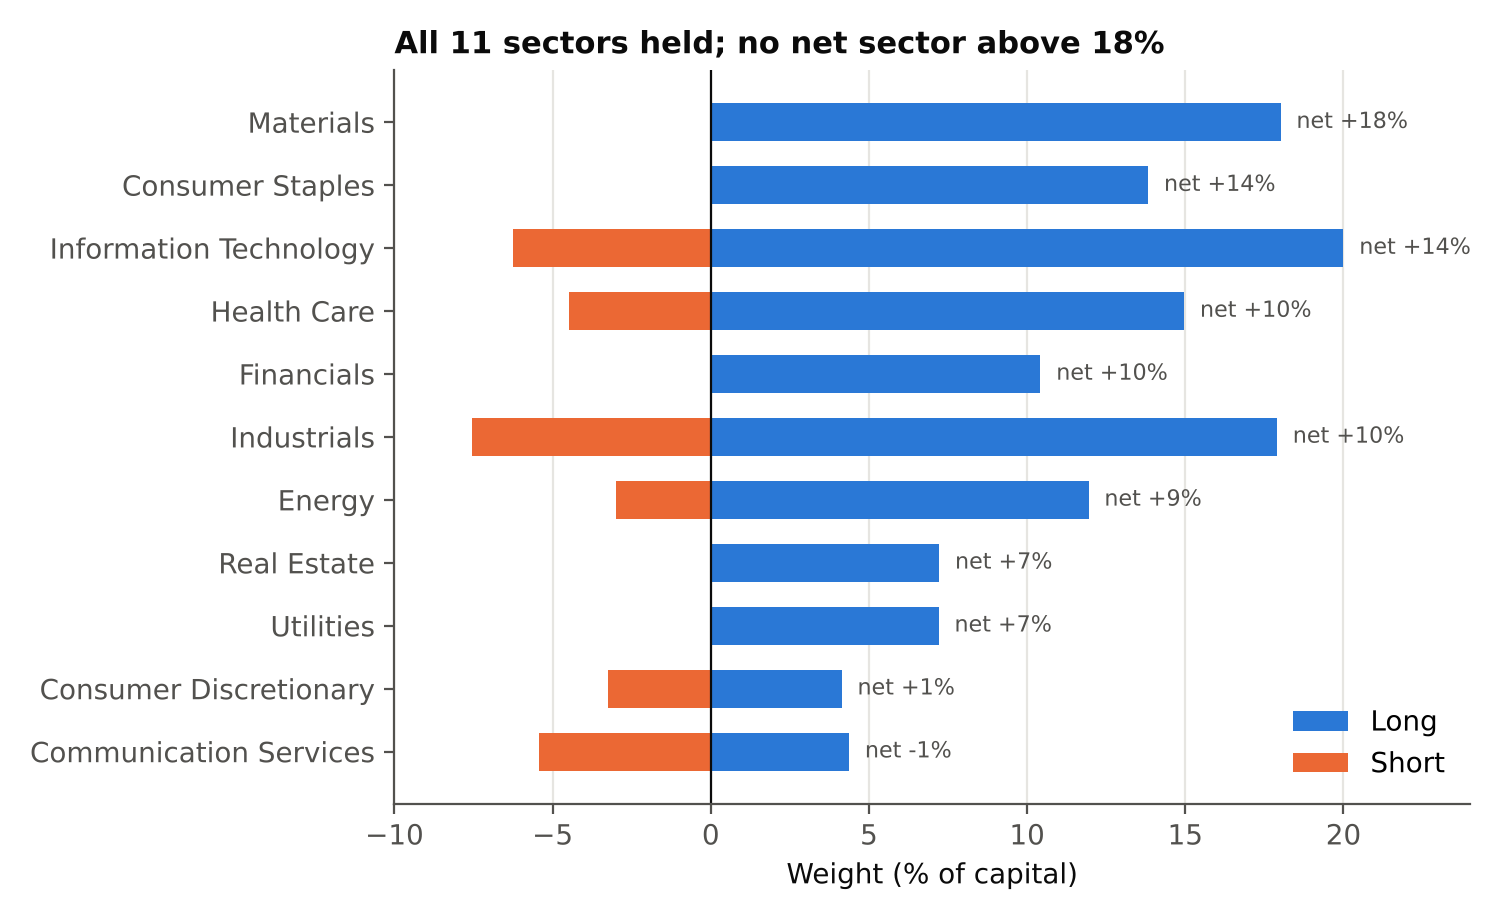

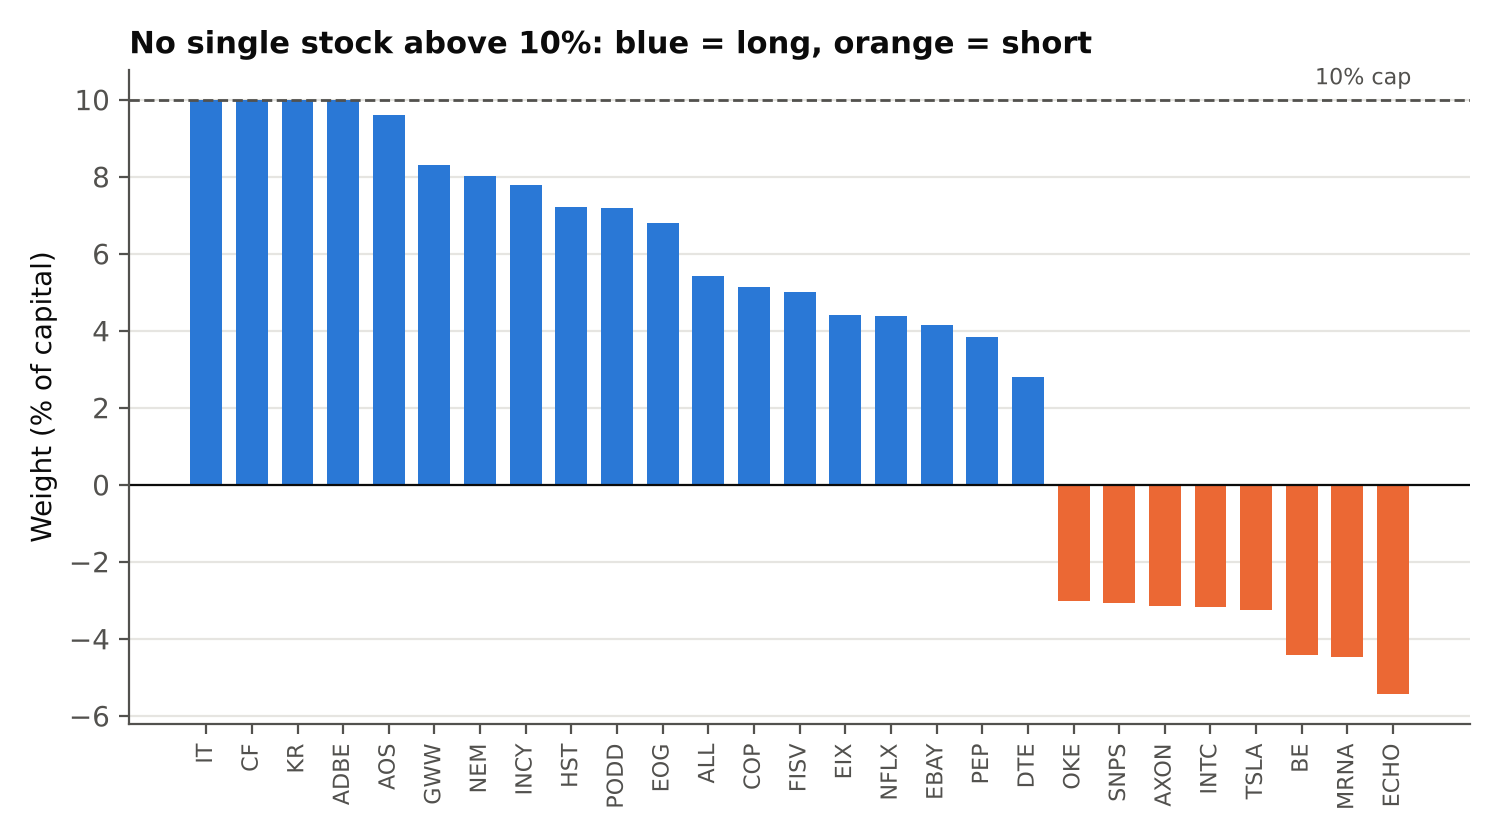

In [5]:
for f in ["chart1_diversification_curve", "chart2_sector_exposure", "chart3_position_sizes"]:
    display(Image(f"output/{f}.png", width=700))

## Step 4 – Diversification with real data: correlations
Monthly returns, Nov 2023 – Oct 2026 (36 months), from S&P Capital IQ. Low correlations between holdings mean their risks largely offset one another.

In [6]:
%run src/correlation.py

Months: 36 2023-11-30 to 2026-10-31
        Pair type  Average correlation
     Long vs long                 0.16
   Short vs short                 0.13
    Long vs short                 0.07
    All 27 stocks                 0.12
Stocks vs S&P 500                 0.23
                 Measure Quality 130/30 S&P 500
           Annual return          -9.6%   24.6%
       Annual volatility          19.8%   12.2%
            Sharpe ratio          -0.70    1.66
         Beta vs S&P 500           0.07    1.00
          Jensen's alpha         -15.4%    0.0%
Correlation with S&P 500           0.04    1.00
          Tracking error          22.8%       –
Weighted avg stock vol: 39.5%  | portfolio beta from Capital IQ 3y betas was 0.16
IT      1.44
CF     -0.10
KR     -0.30
ADBE    1.25
AOS     0.51
GWW     0.72
NEM     0.28
INCY    0.69
HST     1.02
PODD    1.11
EOG    -0.30
ALL     0.27
COP    -0.50
FISV    0.91
EIX    -0.11
NFLX    0.90
EBAY    0.82
PEP     0.25
DTE     0.20
OKE     0.32
SNPS

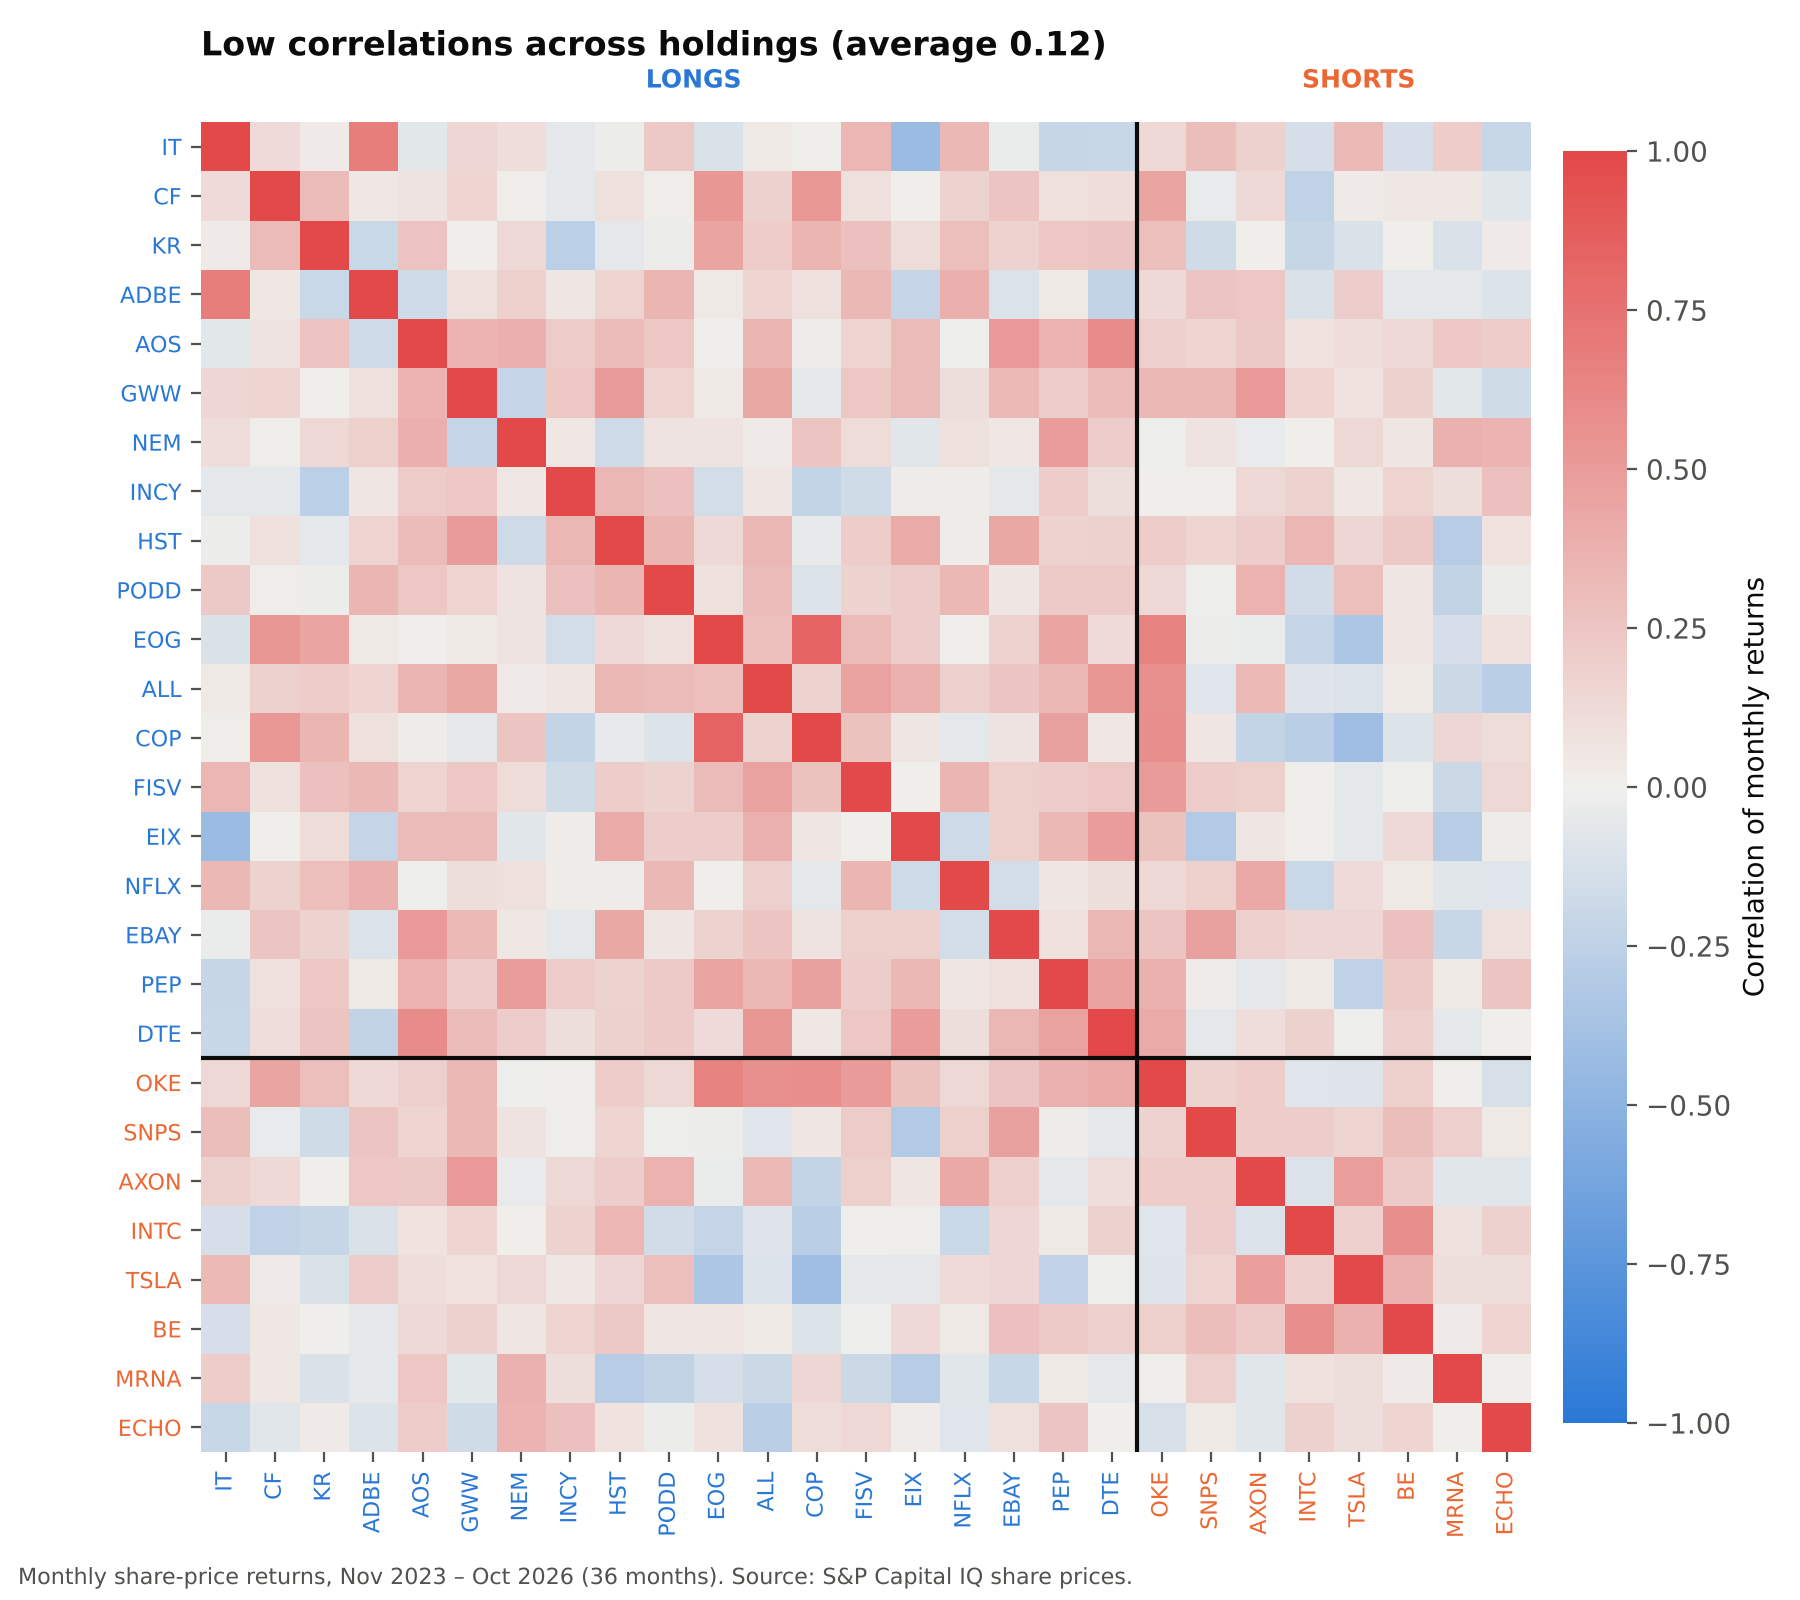

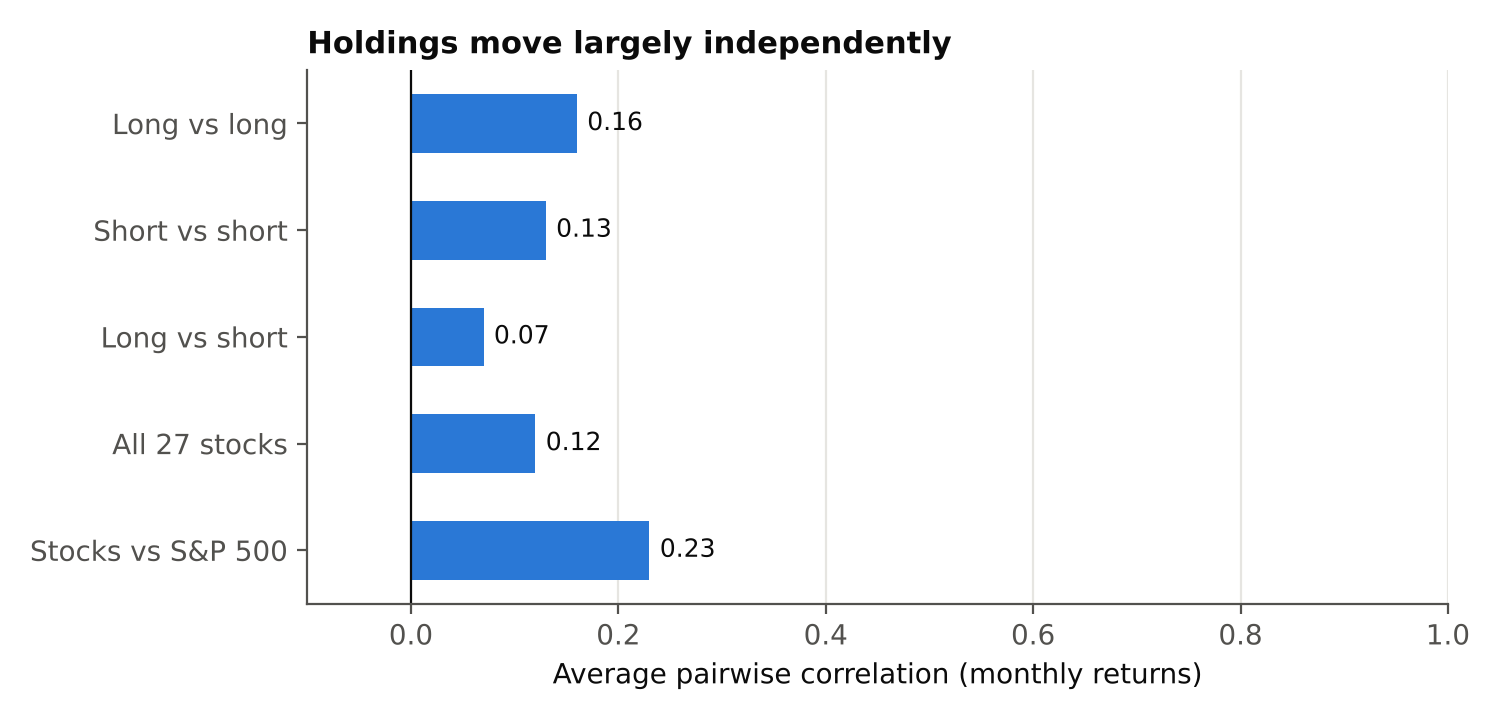

In [7]:
display(Image("output/chart4_correlation_heatmap.png", width=750))
display(Image("output/chart5_correlation_blocks.png", width=650))

**Result:** the average correlation between our 27 holdings is **0.12**, and only **0.07** between long and short positions. Holdings move largely independently, so the portfolio is well diversified across names and sectors.

## Step 5 – Historical risk check and limitations
The table in Step 4 applies today's weights to the last 36 months. It is **not** a valid performance backtest:

1. **Look-ahead bias** – the stocks were selected with today's data.
2. **Short squeeze risk** – several shorts rallied sharply in the speculative/AI boom (Bloom Energy ≈ ×26, EchoStar ≈ ×7), so the short book drove losses and realised volatility (≈20%) well above the model estimate (≈10%). Short losses are unlimited, which is a key trading risk.
3. **Data** – share-price returns (dividends excluded); Capital IQ provides 3-year rather than 5-year betas.

What the history *does* confirm: low correlations (diversification) and a very low market beta (≈0.07), i.e. a defensive, selection-driven portfolio.

## References
- Asness, C., Frazzini, A. & Pedersen, L.H. (2013/2019). Quality Minus Junk. *Review of Accounting Studies*, 24, 34–112.
- Campbell, J.Y., Lettau, M., Malkiel, B.G. & Xu, Y. (2001). Have Individual Stocks Become More Volatile? *Journal of Finance*, 56(1), 1–43.
- Cohen, R., Polk, C. & Silli, B. (2010). Best Ideas. Working paper.
- Evans, J.L. & Archer, S.H. (1968). Diversification and the Reduction of Dispersion. *Journal of Finance*, 23(5), 761–767.
- Statman, M. (1987). How Many Stocks Make a Diversified Portfolio? *Journal of Financial and Quantitative Analysis*, 22(3), 353–363.